## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Lawson Pham

**Date:** 10/12/2026

**Q1**

In [1]:
# Your Phase 1 solution to the problem goes here.
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

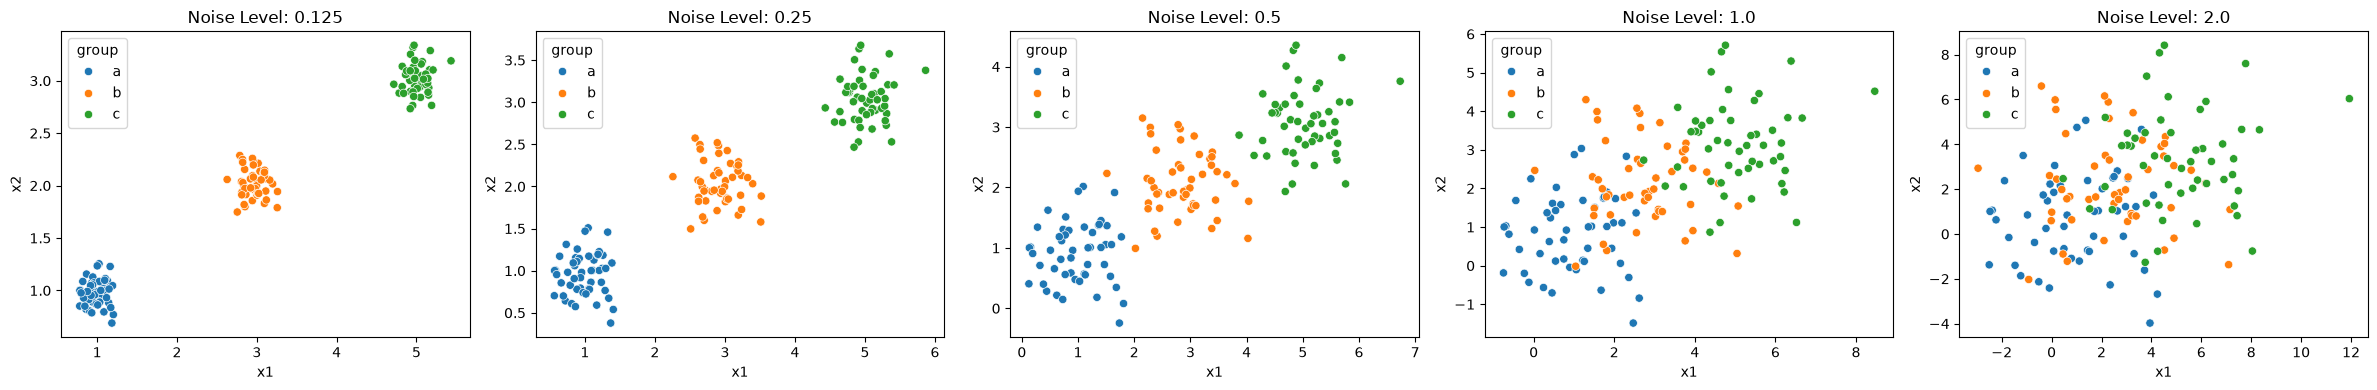

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(24, 4))  
for (noise, df), ax in zip(datasets.items(), axes):
    sns.scatterplot(data=df, x="x1", y="x2", hue="group", ax=ax)
    ax.set_title(f"Noise Level: {noise}")
plt.tight_layout()
plt.show()


As noise increases from 0.125 to 2.0, the points from each group start to mix, not having distinctness in the groups/clusters anymore. The clusters also expand, not having concentrated points.

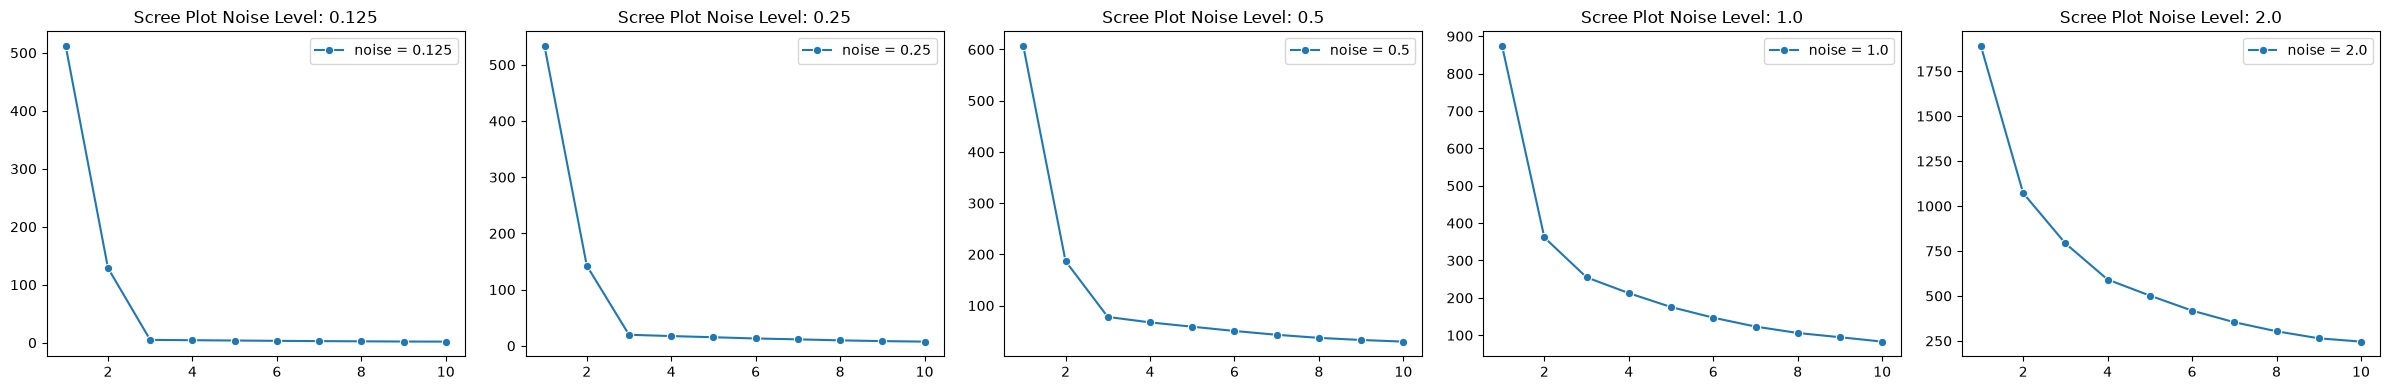

In [3]:
from sklearn.cluster import KMeans

ks = np.arange(1, 11)


fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(24, 4))  
for (noise, df), ax in zip(datasets.items(), axes):
    X = df[["x1", "x2"]] 
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x=ks, y=SSE, label=f"noise = {noise}", marker="o", ax=ax)
    ax.set_title(f"Scree Plot Noise Level: {noise}")
plt.tight_layout()
plt.show()

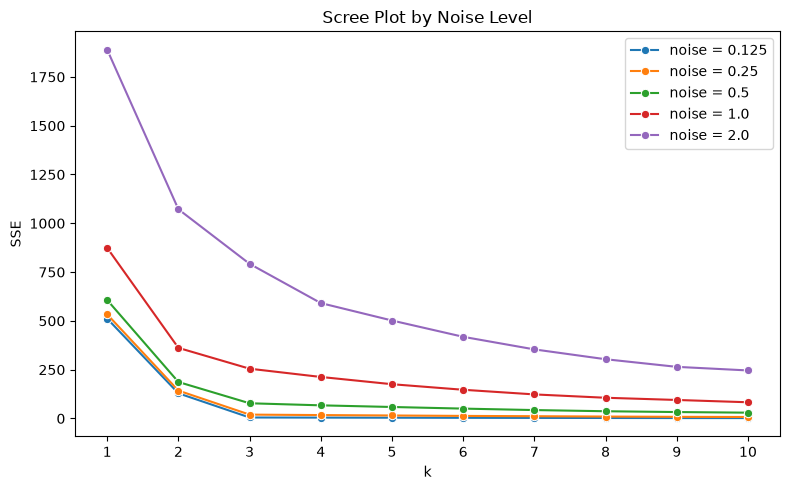

In [4]:
ks = np.arange(1, 11)

plt.figure(figsize=(8, 5))

for noise, df in datasets.items():
    X = df[["x1", "x2"]] 
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x=ks, y=SSE, label=f"noise = {noise}", marker="o")

plt.title("Scree Plot by Noise Level")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.tight_layout()
plt.show()

As the level of noise increases, the SSE is larger, spreading the points out in the group and making the elbow less clear, becoming more curved. This makes choosing k harder as there is not a distinct elbow. Lower noise shows the elbow better and the clusters easier to see.

The intuition of the elbow using this simulation is how each point has x1 and x2 and each is in a different group, with different noise levels for each. The scree helps show the elbow as it shows the SEE for each value of k, and the point where the plot flattens from the steep drop is where the elbow is, which is a reasonable choice for k. When noise increases, this steep drop becomes a curve, adding more uncertainty on picking a good k value.

**Q2**

In [5]:
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv") 

df.columns = df.columns.str.strip()

features = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP",
]

print(df.columns.tolist())

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
data = df.loc[df["Year"].eq(2020)].copy()

print("Rows for 2020:", len(data))
print("Missing values by column:\n", data[features].isna().sum())
print("Duplicate country-year rows:", data.duplicated(["Country", "Year"]).sum())

data = data.dropna(subset=["Country"] + features).copy()
print("Complete rows:", len(data))

['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita']
Rows for 2020: 173
Missing values by column:
 Spending (2020 USD)               23
Spending per Capita               24
Percent of Government Spending    25
Percent of GDP                    23
dtype: int64
Duplicate country-year rows: 0
Complete rows: 148


No further cleaning is required, as there are no duplicate rows for countries and there are 148 countries.

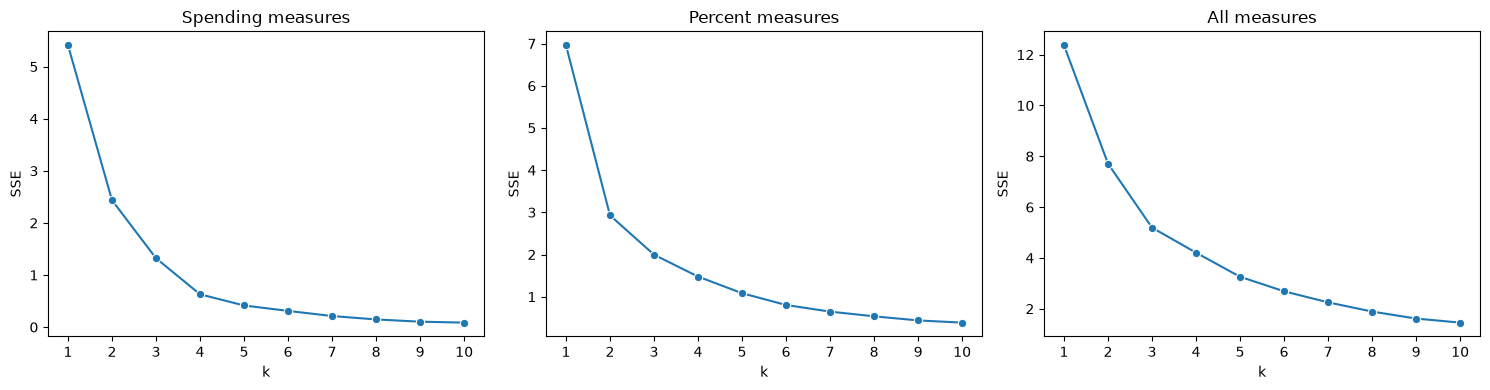

In [6]:

from sklearn.preprocessing import MinMaxScaler

feature_sets = {
    "Spending measures": features[:2],
    "Percent measures": features[2:],
    "All measures": features,
}

# Min-max scale the four numeric measures.
scaler = MinMaxScaler()
scaled = pd.DataFrame(
    scaler.fit_transform(data[features]),
    columns=features,
    index=data.index,
)

ks = np.arange(1, 11)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, cols) in zip(axes, feature_sets.items()):
    X = scaled[cols]
    SSE = [
        KMeans(n_clusters=k, max_iter=300, n_init=10, random_state=0)
        .fit(X).inertia_
        for k in ks
    ]
    sns.lineplot(x=ks, y=SSE, marker="o", ax=ax)
    ax.set(title=name, xlabel="k", ylabel="SSE")
    ax.set_xticks(ks)

plt.tight_layout()
plt.show()

The best k based on the scree plots are 3, 2, and 3.

In [7]:
chosen_k = {
    "Spending measures": 3,
    "Percent measures": 2,
    "All measures": 3,
}

In [8]:
clustered = {}

for name, cols in feature_sets.items():
    X = scaled[cols]
    k = chosen_k[name]

    model = KMeans(
        n_clusters=k,
        max_iter=300,
        n_init=10,
        random_state=0,
    )
    labels = model.fit_predict(X)

    result = data[["Country"] + features].copy()
    result["cluster"] = labels
    clustered[name] = result

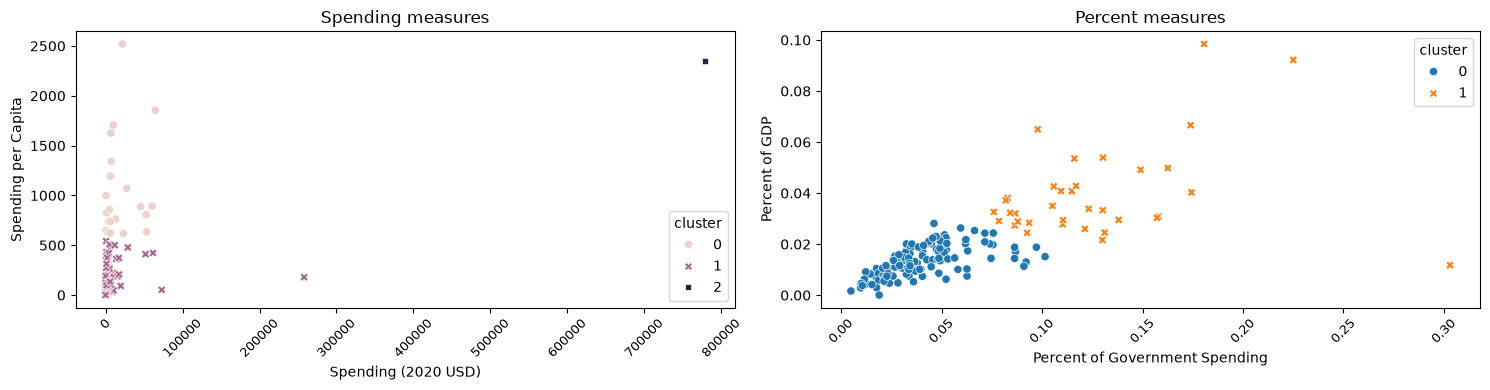

In [9]:
import numpy as np
fig, axes = plt.subplots(1, 2, figsize=(15, 4))

for ax, (name, result) in zip(axes, clustered.items()):
    x_col, y_col = feature_sets[name][:2]
    sns.scatterplot(
        data=result,
        x=x_col,
        y=y_col,
        hue="cluster",
        style="cluster",
        ax=ax,
    )
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=45, labelsize=9)

plt.tight_layout()
plt.show()

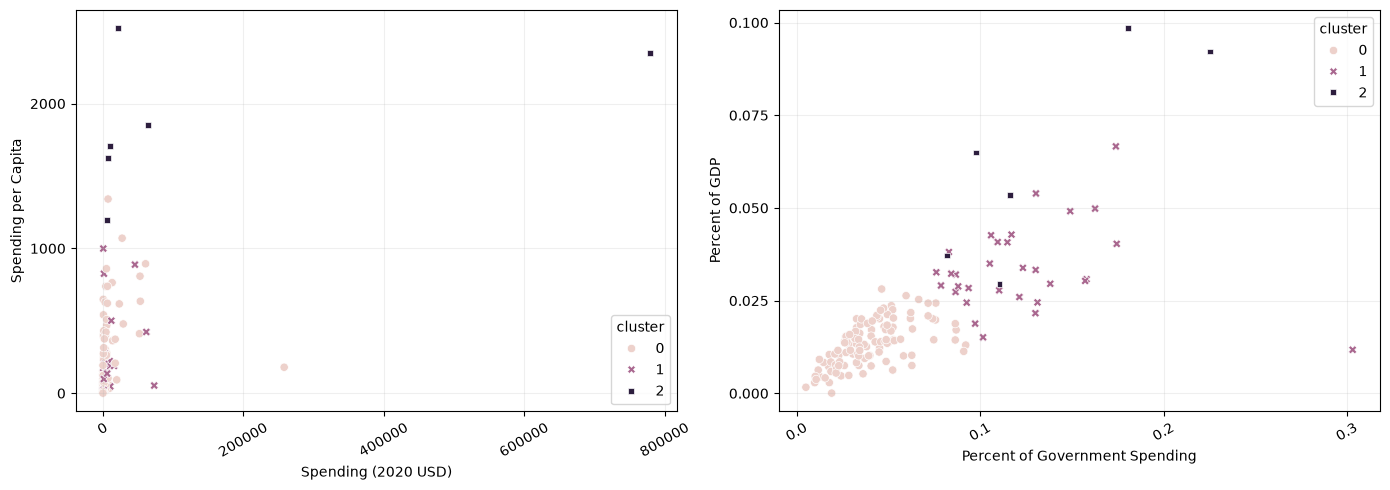

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=clustered["All measures"],
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    style="cluster",
    ax=axes[0]
)

sns.scatterplot(
    data=clustered["All measures"],
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster",
    style="cluster",
    ax=axes[1]
)

for ax in axes:
    ax.tick_params(axis="x", labelrotation=30)
    ax.locator_params(axis="x", nbins=5)
    ax.locator_params(axis="y", nbins=5)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [11]:
for name, result in clustered.items():
    print(f"\n{name}")
    display(
        result.groupby("cluster").describe()
    )


Spending measures


Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      21.0  1046.433509  ...                       0.110270   
1                     126.0   122.034996  ...                       0.077917   
2                       1.0  2351.631858  ...                       0.081976   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.225050           21.0  0.030649  0.026206  0.006273  0.014159   
1        0.303027          126.0  0.017641  0.011359  0.000054  0.010145   
2        0.081976            1.0  0.037179       NaN  0.037179  0.037179   

                                       
              50%       75%       max  
cluster                                
0        0.020095  0.040744  0.098470  
1        0.014535  0.022357  0.066600  
2        0.037179  0.037179  0.037179  

[3 rows x 32 columns]


Percent measures


Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                     113.0   7068.004683   26254.019225    8.622460   
1                      35.0  32802.003598  131164.138616  163.926877   

                                                              \
                25%          50%          75%            max   
cluster                                                        
0        131.104409   567.650747  4087.541320  257973.429834   
1        613.913142  2237.764706  9843.424434  778397.200000   

        Spending per Capita              ... Percent of Government Spending  \
                      count        mean  ...                            75%   
cluster                                  ...                                  
0                     113.0  198.896006  ...                       0.051496   
1                      35.0  492.225610  ...                       0.143584   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501          113.0  0.013481  0.005966  0.000054  0.009147   
1        0.303027           35.0  0.039433  0.018179  0.011742  0.028962   

                                       
              50%       75%       max  
cluster                                
0        0.013631  0.017830  0.028132  
1        0.033281  0.042722  0.098470  

[2 rows x 32 columns]


All measures


Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                     111.0   196.926833  ...                       0.050505   
1                      31.0   212.689100  ...                       0.134663   
2                       6.0  1875.150751  ...                       0.164503   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1        0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                       
              50%       75%       max  
cluster                                
0        0.013589  0.017769  0.028132  
1        0.032024  0.040531  0.066600  
2        0.059257  0.085398  0.098470  

[3 rows x 32 columns]

In [12]:
clustered["Spending measures"].loc[
    clustered["Spending measures"]["cluster"] == 2,
    ["Country", "cluster", "Spending (2020 USD)", "Spending per Capita"]
]

,Country,cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


`Spending (2020 USD)` and `Spending per Capita`: Cluster 1 contains the most amount of countries, with low military spending. Cluster 0 has a higher average of spending, and cluster 2 has only one country, with the most spending. The United States is in the 2nd cluster, because of the high military spending. Patterns I see in membership is that most countries have low spending, with the US being an outlier, having its own cluster.

`Percent of Government Spending` and `Percent of GDP`: Cluster 0 has the most amount of countries, with the least percentage of spending. Cluster 1 has a higher average percentage of spending. Compared to part 2, since this plot has a k value of 2, there is not a third cluster to compare. The main difference is this is now compared by percentage of spending compared to how much money they contribute, so countries who contribute the same percentage will be in the same clusters.

All: Compared to the previous two parts, cluster 0 has the most amount of countries, with lowest average spending and lowest percentage of GDP. Compared to part 2, cluster 2 with the highest spending now contains more countries. This shows how combining all four variables will change cluster membership because it will show both spending and spending compared to percentage.

The $k$-MC algorithm was useful because it showed patterns in countries in their spending on the military. A pattern is that most countries have relatively low spending with only a few with high spending compared to their GDP.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** ba49661c97be7c354b64de4dc19265999083b4aa
- **AI tool and model used:** ChatGPT-6

### *Prompts used

1. How can I improve my code?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Fix your clustering visualizations (cells 21–22) Cell 21: You're only plotting two of your three feature sets
2. Improve your K-Means code by removing repetition
In cells 10, 11, and 17, you repeatedly calculate SSE using nearly identical code.
You can simplify this by creating a helper function:
3. Improve how you analyze clusters
Your current code:
result.groupby("cluster").describe()
This is correct, but the output is quite large.
For your military spending analysis, I would add a smaller summary table
4. Improve your normalization
You correctly use MinMaxScaler, which is what your assignment requests.
However, military spending data can have extreme outliers. Min-max normalization compresses most countries into a relatively small range when one country has exceptionally high spending.
I would keep min-max normalization for the assignment but consider adding a comparison using StandardScaler to investigate how sensitive the clusters are to scaling.

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept | I have my third feature set on a different plot right below to show all four features, but adding it on the row on top would not hurt. |
| 2 | Accept | This will help with not repetiting code. |
| 3 | reject | I am using the code like the assignment requests, no need to change. |
| 4 | reject | I am using what the assignment requests, it will make sure my results is what should be outputted. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

**Q1**

In [18]:
# Your Phase 2 solution to the problem goes here.
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

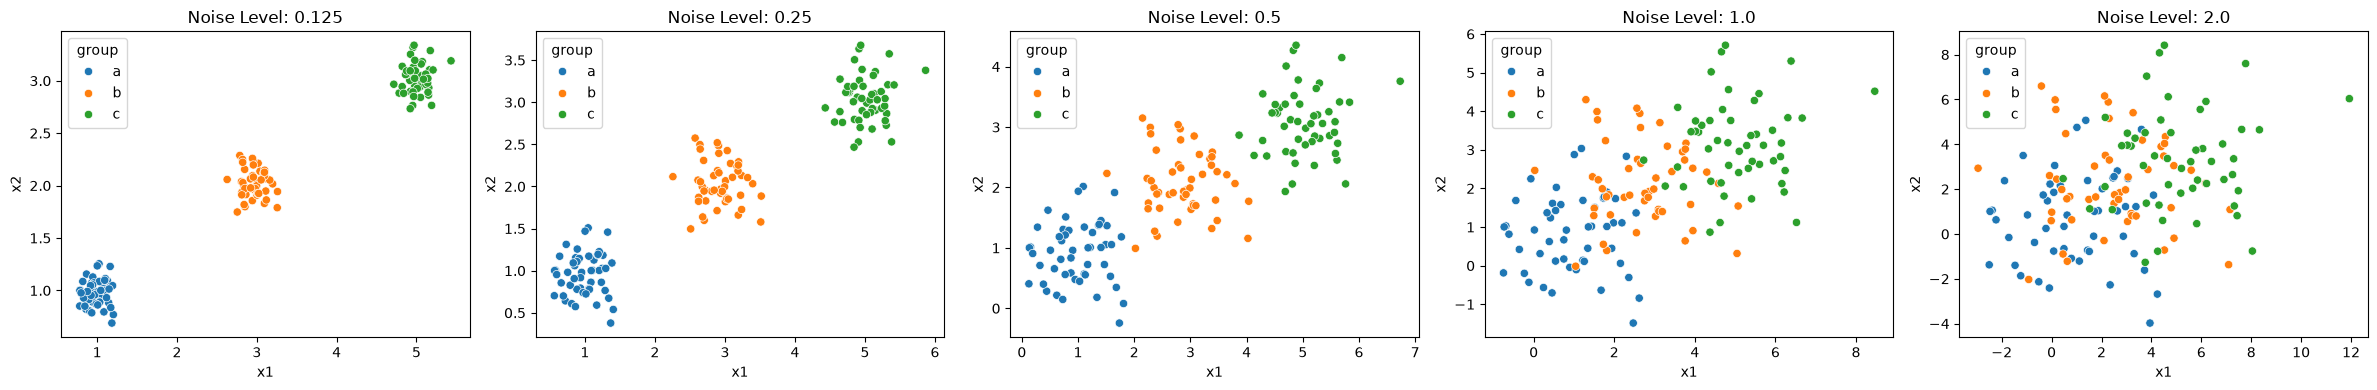

In [19]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

datasets = {
    0.125: df0_125,
    0.25: df0_25,
    0.5: df0_5,
    1.0: df1_0,
    2.0: df2_0
}

fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(24, 4))  
for (noise, df), ax in zip(datasets.items(), axes):
    sns.scatterplot(data=df, x="x1", y="x2", hue="group", ax=ax)
    ax.set_title(f"Noise Level: {noise}")
plt.tight_layout()
plt.show()


As noise increases from 0.125 to 2.0, the points from each group start to mix, not having distinctness in the groups/clusters anymore. The clusters also expand, not having concentrated points.

In [20]:
from sklearn.cluster import KMeans

def calculate_sse(X, ks):
    return [
        KMeans(
            n_clusters=k,
            max_iter=300,
            n_init=10,
            random_state=0
        ).fit(X).inertia_
        for k in ks
    ]

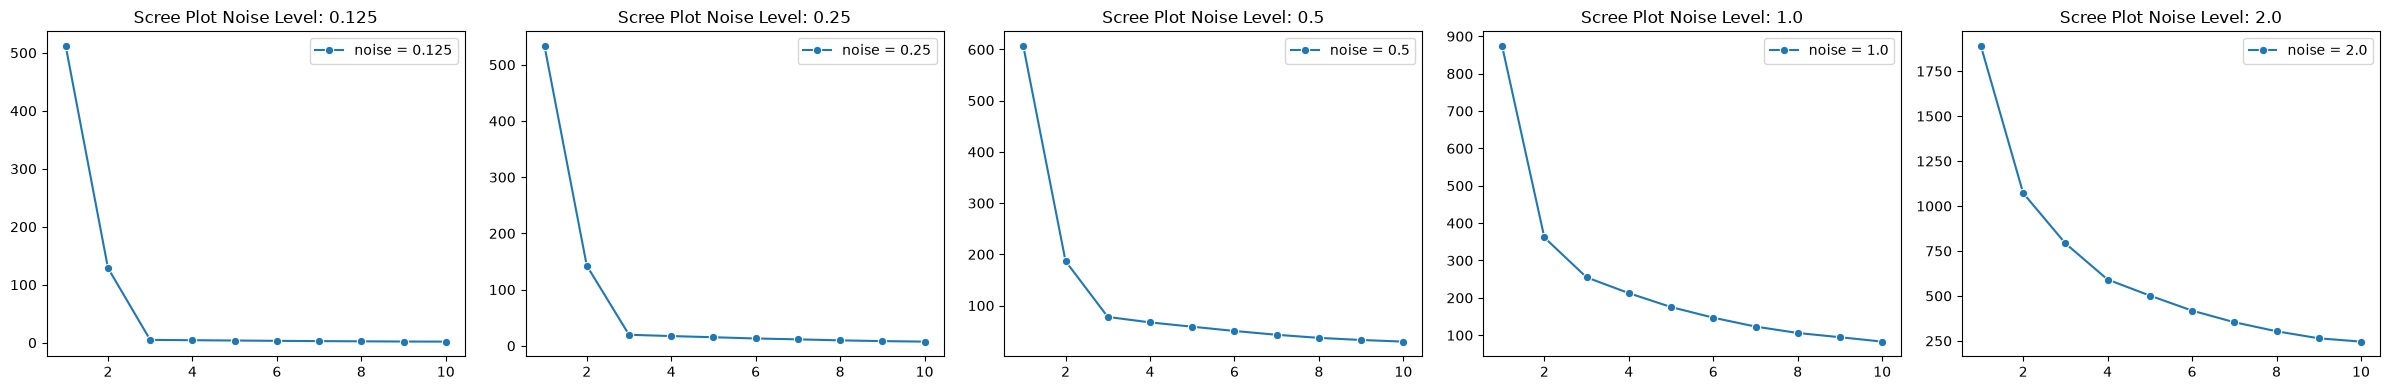

In [21]:
ks = np.arange(1, 11)


fig, axes = plt.subplots(nrows=1, ncols=5, figsize=(24, 4))  
for (noise, df), ax in zip(datasets.items(), axes):
    X = df[["x1", "x2"]] 
    SSE = calculate_sse(X, ks)
    sns.lineplot(x=ks, y=SSE, label=f"noise = {noise}", marker="o", ax=ax)
    ax.set_title(f"Scree Plot Noise Level: {noise}")
plt.tight_layout()
plt.show()

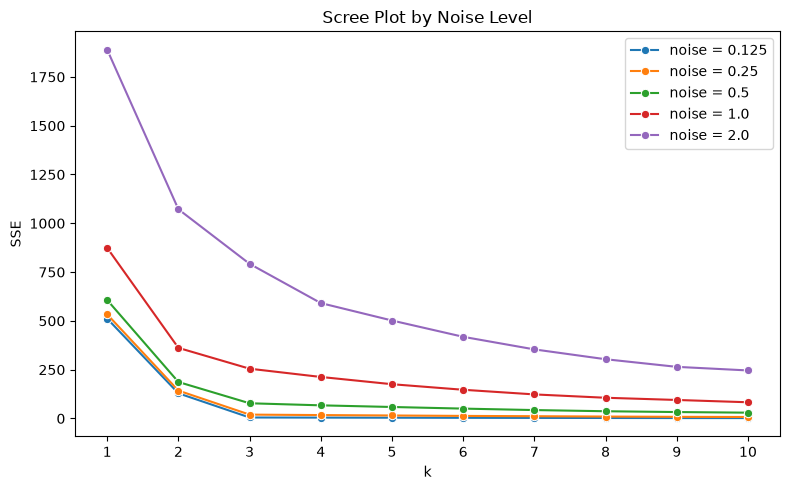

In [22]:
ks = np.arange(1, 11)

plt.figure(figsize=(8, 5))

for noise, df in datasets.items():
    X = df[["x1", "x2"]] 
    SSE = calculate_sse(X, ks)
    sns.lineplot(x=ks, y=SSE, label=f"noise = {noise}", marker="o")

plt.title("Scree Plot by Noise Level")
plt.xlabel("k")
plt.ylabel("SSE")
plt.xticks(ks)
plt.tight_layout()
plt.show()

As the level of noise increases, the SSE is larger, spreading the points out in the group and making the elbow less clear, becoming more curved. This makes choosing k harder as there is not a distinct elbow. Lower noise shows the elbow better and the clusters easier to see.

The intuition of the elbow using this simulation is how each point has x1 and x2 and each is in a different group, with different noise levels for each. The scree helps show the elbow as it shows the SEE for each value of k, and the point where the plot flattens from the steep drop is where the elbow is, which is a reasonable choice for k. When noise increases, this steep drop becomes a curve, adding more uncertainty on picking a good k value.

**Q2**

In [23]:
df = pd.read_csv("./data/SIPRI Military Expenditure Database.csv") 

df.columns = df.columns.str.strip()

features = [
    "Spending (2020 USD)",
    "Spending per Capita",
    "Percent of Government Spending",
    "Percent of GDP",
]

print(df.columns.tolist())

df["Year"] = pd.to_numeric(df["Year"], errors="coerce")
data = df.loc[df["Year"].eq(2020)].copy()

print("Rows for 2020:", len(data))
print("Missing values by column:\n", data[features].isna().sum())
print("Duplicate country-year rows:", data.duplicated(["Country", "Year"]).sum())

data = data.dropna(subset=["Country"] + features).copy()
print("Complete rows:", len(data))

['index', 'Year', 'Country', 'Spending (2020 USD)', 'Percent of GDP', 'Percent of Government Spending', 'Spending per Capita']
Rows for 2020: 173
Missing values by column:
 Spending (2020 USD)               23
Spending per Capita               24
Percent of Government Spending    25
Percent of GDP                    23
dtype: int64
Duplicate country-year rows: 0
Complete rows: 148


No further cleaning is required, as there are no duplicate rows for countries and there are 148 countries.

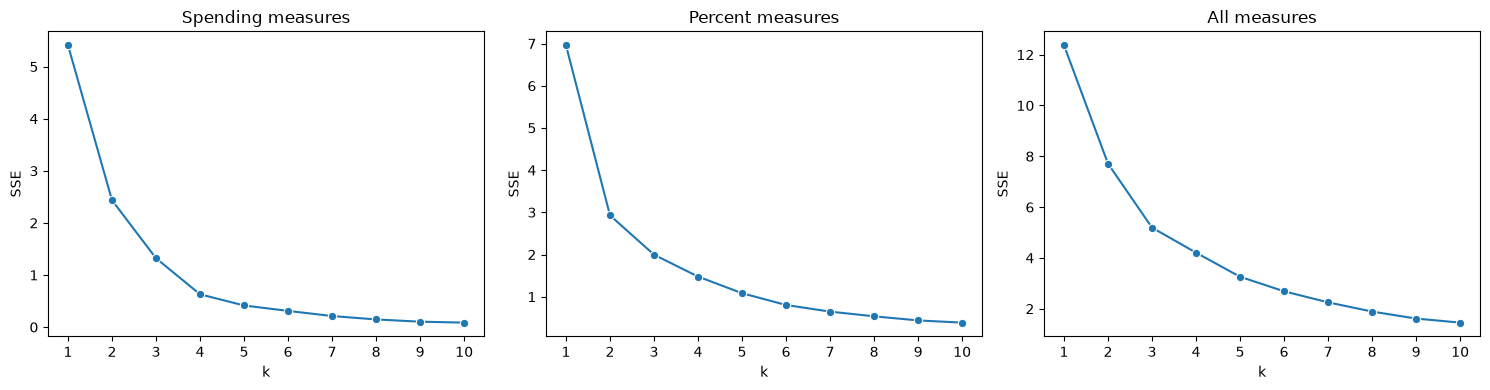

In [24]:

from sklearn.preprocessing import MinMaxScaler

feature_sets = {
    "Spending measures": features[:2],
    "Percent measures": features[2:],
    "All measures": features,
}

# Min-max scale the four numeric measures.
scaler = MinMaxScaler()
scaled = pd.DataFrame(
    scaler.fit_transform(data[features]),
    columns=features,
    index=data.index,
)

ks = np.arange(1, 11)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, cols) in zip(axes, feature_sets.items()):
    X = scaled[cols]
    SSE = calculate_sse(X, ks)
    sns.lineplot(x=ks, y=SSE, marker="o", ax=ax)
    ax.set(title=name, xlabel="k", ylabel="SSE")
    ax.set_xticks(ks)

plt.tight_layout()
plt.show()

The best k based on the scree plots are 3, 2, and 3.

In [25]:
chosen_k = {
    "Spending measures": 3,
    "Percent measures": 2,
    "All measures": 3,
}

In [26]:
clustered = {}

for name, cols in feature_sets.items():
    X = scaled[cols]
    k = chosen_k[name]

    model = KMeans(
        n_clusters=k,
        max_iter=300,
        n_init=10,
        random_state=0,
    )
    labels = model.fit_predict(X)

    result = data[["Country"] + features].copy()
    result["cluster"] = labels
    clustered[name] = result

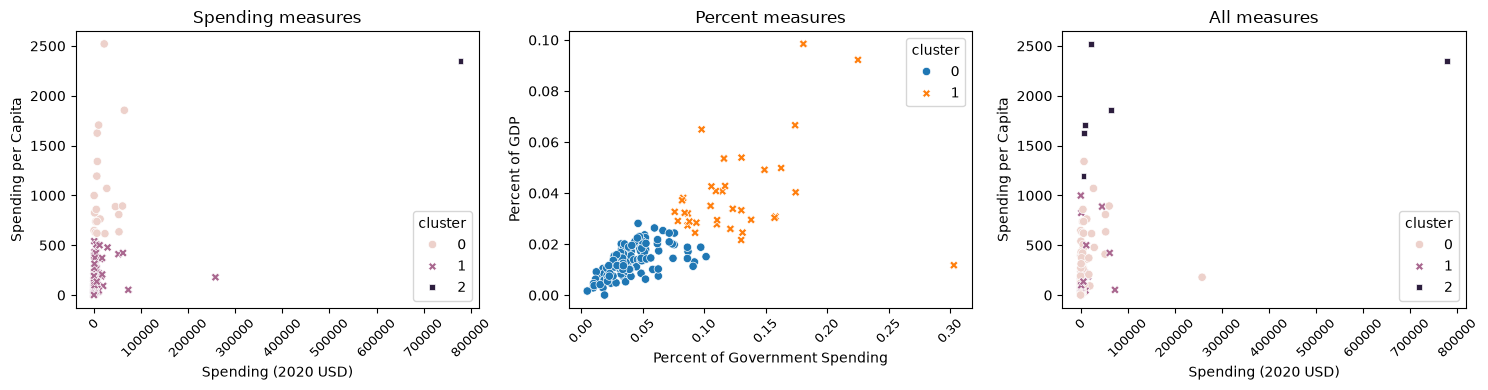

In [27]:
import numpy as np
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, result) in zip(axes, clustered.items()):
    x_col, y_col = feature_sets[name][:2]
    sns.scatterplot(
        data=result,
        x=x_col,
        y=y_col,
        hue="cluster",
        style="cluster",
        ax=ax,
    )
    ax.set_title(name)
    ax.tick_params(axis="x", labelrotation=45, labelsize=9)

plt.tight_layout()
plt.show()

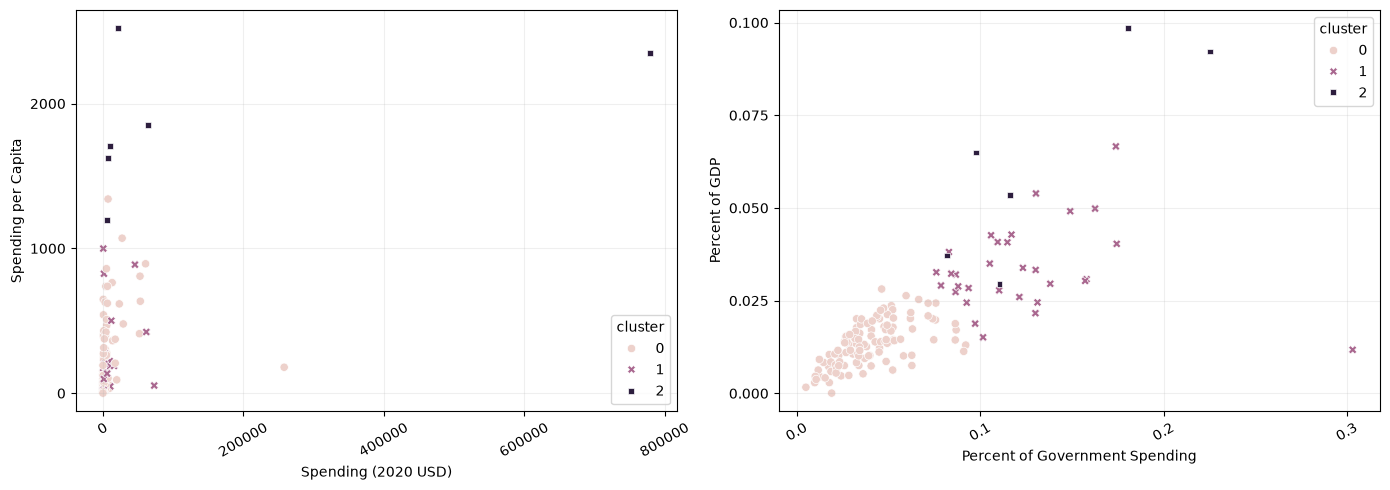

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.scatterplot(
    data=clustered["All measures"],
    x="Spending (2020 USD)",
    y="Spending per Capita",
    hue="cluster",
    style="cluster",
    ax=axes[0]
)

sns.scatterplot(
    data=clustered["All measures"],
    x="Percent of Government Spending",
    y="Percent of GDP",
    hue="cluster",
    style="cluster",
    ax=axes[1]
)

for ax in axes:
    ax.tick_params(axis="x", labelrotation=30)
    ax.locator_params(axis="x", nbins=5)
    ax.locator_params(axis="y", nbins=5)
    ax.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [29]:
for name, result in clustered.items():
    print(f"\n{name}")
    display(
        result.groupby("cluster").describe()
    )


Spending measures


Spending (2020 USD)                                              \
                      count           mean           std            min   
cluster                                                                   
0                      21.0   19975.991473  21749.736747     405.790494   
1                     126.0    5943.346303  24858.961064       8.622460   
2                       1.0  778397.200000           NaN  778397.200000   

                                                                     \
                   25%            50%            75%            max   
cluster                                                               
0          4980.428135    7269.880030   27300.894701   64558.400000   
1           162.761743     580.758315    3225.333414  257973.429834   
2        778397.200000  778397.200000  778397.200000  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                      21.0  1046.433509  ...                       0.110270   
1                     126.0   122.034996  ...                       0.077917   
2                       1.0  2351.631858  ...                       0.081976   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.225050           21.0  0.030649  0.026206  0.006273  0.014159   
1        0.303027          126.0  0.017641  0.011359  0.000054  0.010145   
2        0.081976            1.0  0.037179       NaN  0.037179  0.037179   

                                       
              50%       75%       max  
cluster                                
0        0.020095  0.040744  0.098470  
1        0.014535  0.022357  0.066600  
2        0.037179  0.037179  0.037179  

[3 rows x 32 columns]


Percent measures


Spending (2020 USD)                                           \
                      count          mean            std         min   
cluster                                                                
0                     113.0   7068.004683   26254.019225    8.622460   
1                      35.0  32802.003598  131164.138616  163.926877   

                                                              \
                25%          50%          75%            max   
cluster                                                        
0        131.104409   567.650747  4087.541320  257973.429834   
1        613.913142  2237.764706  9843.424434  778397.200000   

        Spending per Capita              ... Percent of Government Spending  \
                      count        mean  ...                            75%   
cluster                                  ...                                  
0                     113.0  198.896006  ...                       0.051496   
1                      35.0  492.225610  ...                       0.143584   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.101501          113.0  0.013481  0.005966  0.000054  0.009147   
1        0.303027           35.0  0.039433  0.018179  0.011742  0.028962   

                                       
              50%       75%       max  
cluster                                
0        0.013631  0.017830  0.028132  
1        0.033281  0.042722  0.098470  

[2 rows x 32 columns]


All measures


Spending (2020 USD)                                             \
                      count           mean            std          min   
cluster                                                                  
0                     111.0    7086.472777   26479.379918     8.622460   
1                      31.0    8786.086602   17901.909108   162.373364   
2                       6.0  147964.582042  309635.189564  6095.708713   

                                                                 \
                 25%           50%           75%            max   
cluster                                                           
0         130.010211    567.650747   3910.107493  257973.429834   
1         467.787851   1404.787234   7739.166193   72937.064048   
2        7700.424616  15897.570598  53872.942442  778397.200000   

        Spending per Capita               ... Percent of Government Spending  \
                      count         mean  ...                            75%   
cluster                                   ...                                  
0                     111.0   196.926833  ...                       0.050505   
1                      31.0   212.689100  ...                       0.134663   
2                       6.0  1875.150751  ...                       0.164503   

                  Percent of GDP                                          \
              max          count      mean       std       min       25%   
cluster                                                                    
0        0.092044          111.0  0.013419  0.005996  0.000054  0.008873   
1        0.303027           31.0  0.033492  0.011449  0.011742  0.027560   
2        0.225050            6.0  0.062634  0.028275  0.029429  0.041272   

                                       
              50%       75%       max  
cluster                                
0        0.013589  0.017769  0.028132  
1        0.032024  0.040531  0.066600  
2        0.059257  0.085398  0.098470  

[3 rows x 32 columns]

In [30]:
clustered["Spending measures"].loc[
    clustered["Spending measures"]["cluster"] == 2,
    ["Country", "cluster", "Spending (2020 USD)", "Spending per Capita"]
]

,Country,cluster,Spending (2020 USD),Spending per Capita
5540,United States of America,2,778397.2,2351.631858


`Spending (2020 USD)` and `Spending per Capita`: Cluster 1 contains the most amount of countries, with low military spending. Cluster 0 has a higher average of spending, and cluster 2 has only one country, with the most spending. The United States is in the 2nd cluster, because of the high military spending. Patterns I see in membership is that most countries have low spending, with the US being an outlier, having its own cluster.

`Percent of Government Spending` and `Percent of GDP`: Cluster 0 has the most amount of countries, with the least percentage of spending. Cluster 1 has a higher average percentage of spending. Compared to part 2, since this plot has a k value of 2, there is not a third cluster to compare. The main difference is this is now compared by percentage of spending compared to how much money they contribute, so countries who contribute the same percentage will be in the same clusters.

All: Compared to the previous two parts, cluster 0 has the most amount of countries, with lowest average spending and lowest percentage of GDP. Compared to part 2, cluster 2 with the highest spending now contains more countries. This shows how combining all four variables will change cluster membership because it will show both spending and spending compared to percentage.

The $k$-MC algorithm was useful because it showed patterns in countries in their spending on the military. A pattern is that most countries have relatively low spending with only a few with high spending compared to their GDP.

### *Reflection on AI assistance
In your own words without generative AI.

The main improvements that AI provided was removing repetitive code, making the code easier to read, and suggesting changes that will help pick more accurate values. Removing the repetitve SSE calculation I was using to create a function helped with making the code easier to read and shorter as well, giving the same results as before. It also suggested not using describe() as it was too large, and also for MinMaxScaler(), comparing it to StandardScaler, to see the difference since the data could have extreme outliers that could skew the results. For the cluster graphs of the four measures, I had graphed the first two side by side, and the graph with all four measure in a different cell after, so that I will be able to plot it showing the measures since it can only be plotted with two measures. AI read this and thought I did not include the graph of all four measures, and told me to add another graph next to the first two, which I added just for helpful visual purposes. This was a limitation as in the instructions of the assignment, it says to use describe() and MinMaxScaler(), and it is more focused on clean, and good code instead of the instructions. The final solution was verified by running all the cells and then comparing the graphs from phase 1 to phase 2, making sure the graphs are the same. 